# 06 — RNN / LSTM: monthly foldable sentiment forecast

**Engine 5** of the CanNothingFold business case: does foldable review
sentiment trend up or down towards a 2027 launch, and does timing matter?

> **Honesty first.** The sentiment series is built from notebook 04's per-review
> VADER output — a **synthetic-like corpus (110 unique texts)**. The series is
> also **thin: 37 monthly points (2022-10 .. 2025-10)**, far below the 60–80
> points the build plan hoped for. Expect weak absolute accuracy; the graded
> evidence here is the **naive last-value baseline comparison**, not the LSTM's
> raw error. The 2027 launch quarters lie well beyond any defensible forecast
> horizon from a 37-month series — the launch-timing recommendation therefore
> leans on the observed range and trend, with the forecast as supporting
> context only.

**Method:** 6-month input windows (sentiment + review volume) → LSTM → next
month; evaluated walk-forward at 1/2/3-month horizons against the naive
last-value baseline; then a 12-month recursive forecast from the series end
(5-seed ensemble for an uncertainty band).

**Outputs**
- `results/sentiment_forecast_metrics.csv` — LSTM vs naive, RMSE/MAE per horizon
- `results/sentiment_forecast.csv` — 12-month forecast with ensemble band
- `figures/06_sentiment_series.png`, `figures/06_sentiment_forecast.png` (300 dpi)

In [1]:
import os
import random
import warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore", message=".*encountered in matmul")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
from tensorflow import keras
tf.random.set_seed(SEED)
tf.get_logger().setLevel("ERROR")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, FIGURES = PROJECT_ROOT / "results", PROJECT_ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 300

WINDOW, HORIZON = 6, 3
print("setup ok")

/Users/jerin/Developer/CanNothingFold/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


setup ok


## 1. Monthly sentiment series (from notebook 04's per-review output)

In [2]:
sent = pd.read_csv(RESULTS / "foldable_reviews_sentiment.csv")
monthly = (sent.groupby("review_month")
           .agg(mean_compound=("vader_compound", "mean"),
                reviews=("review_id", "size"))
           .sort_index().reset_index())
months = monthly.review_month.tolist()
y = monthly.mean_compound.to_numpy()
volume = np.log1p(monthly.reviews.to_numpy())

trend_slope = np.polyfit(np.arange(len(y)), y, 1)[0]
print(f"months: {len(monthly)}  ({months[0]} .. {months[-1]})")
print(f"sentiment: min {y.min():.3f} / mean {y.mean():.3f} / max {y.max():.3f} "
      f"(std {y.std():.4f})")
print(f"linear trend: {trend_slope:+.5f} per month "
      f"(~{12 * trend_slope:+.3f} per year, i.e. essentially flat)")
monthly.tail(6)

months: 37  (2022-10 .. 2025-10)
sentiment: min 0.348 / mean 0.415 / max 0.505 (std 0.0392)
linear trend: +0.00012 per month (~+0.001 per year, i.e. essentially flat)


,review_month,mean_compound,reviews
31,2025-05,0.369214,111
32,2025-06,0.389854,123
33,2025-07,0.450484,119
34,2025-08,0.417178,119
35,2025-09,0.451286,129
36,2025-10,0.463903,65


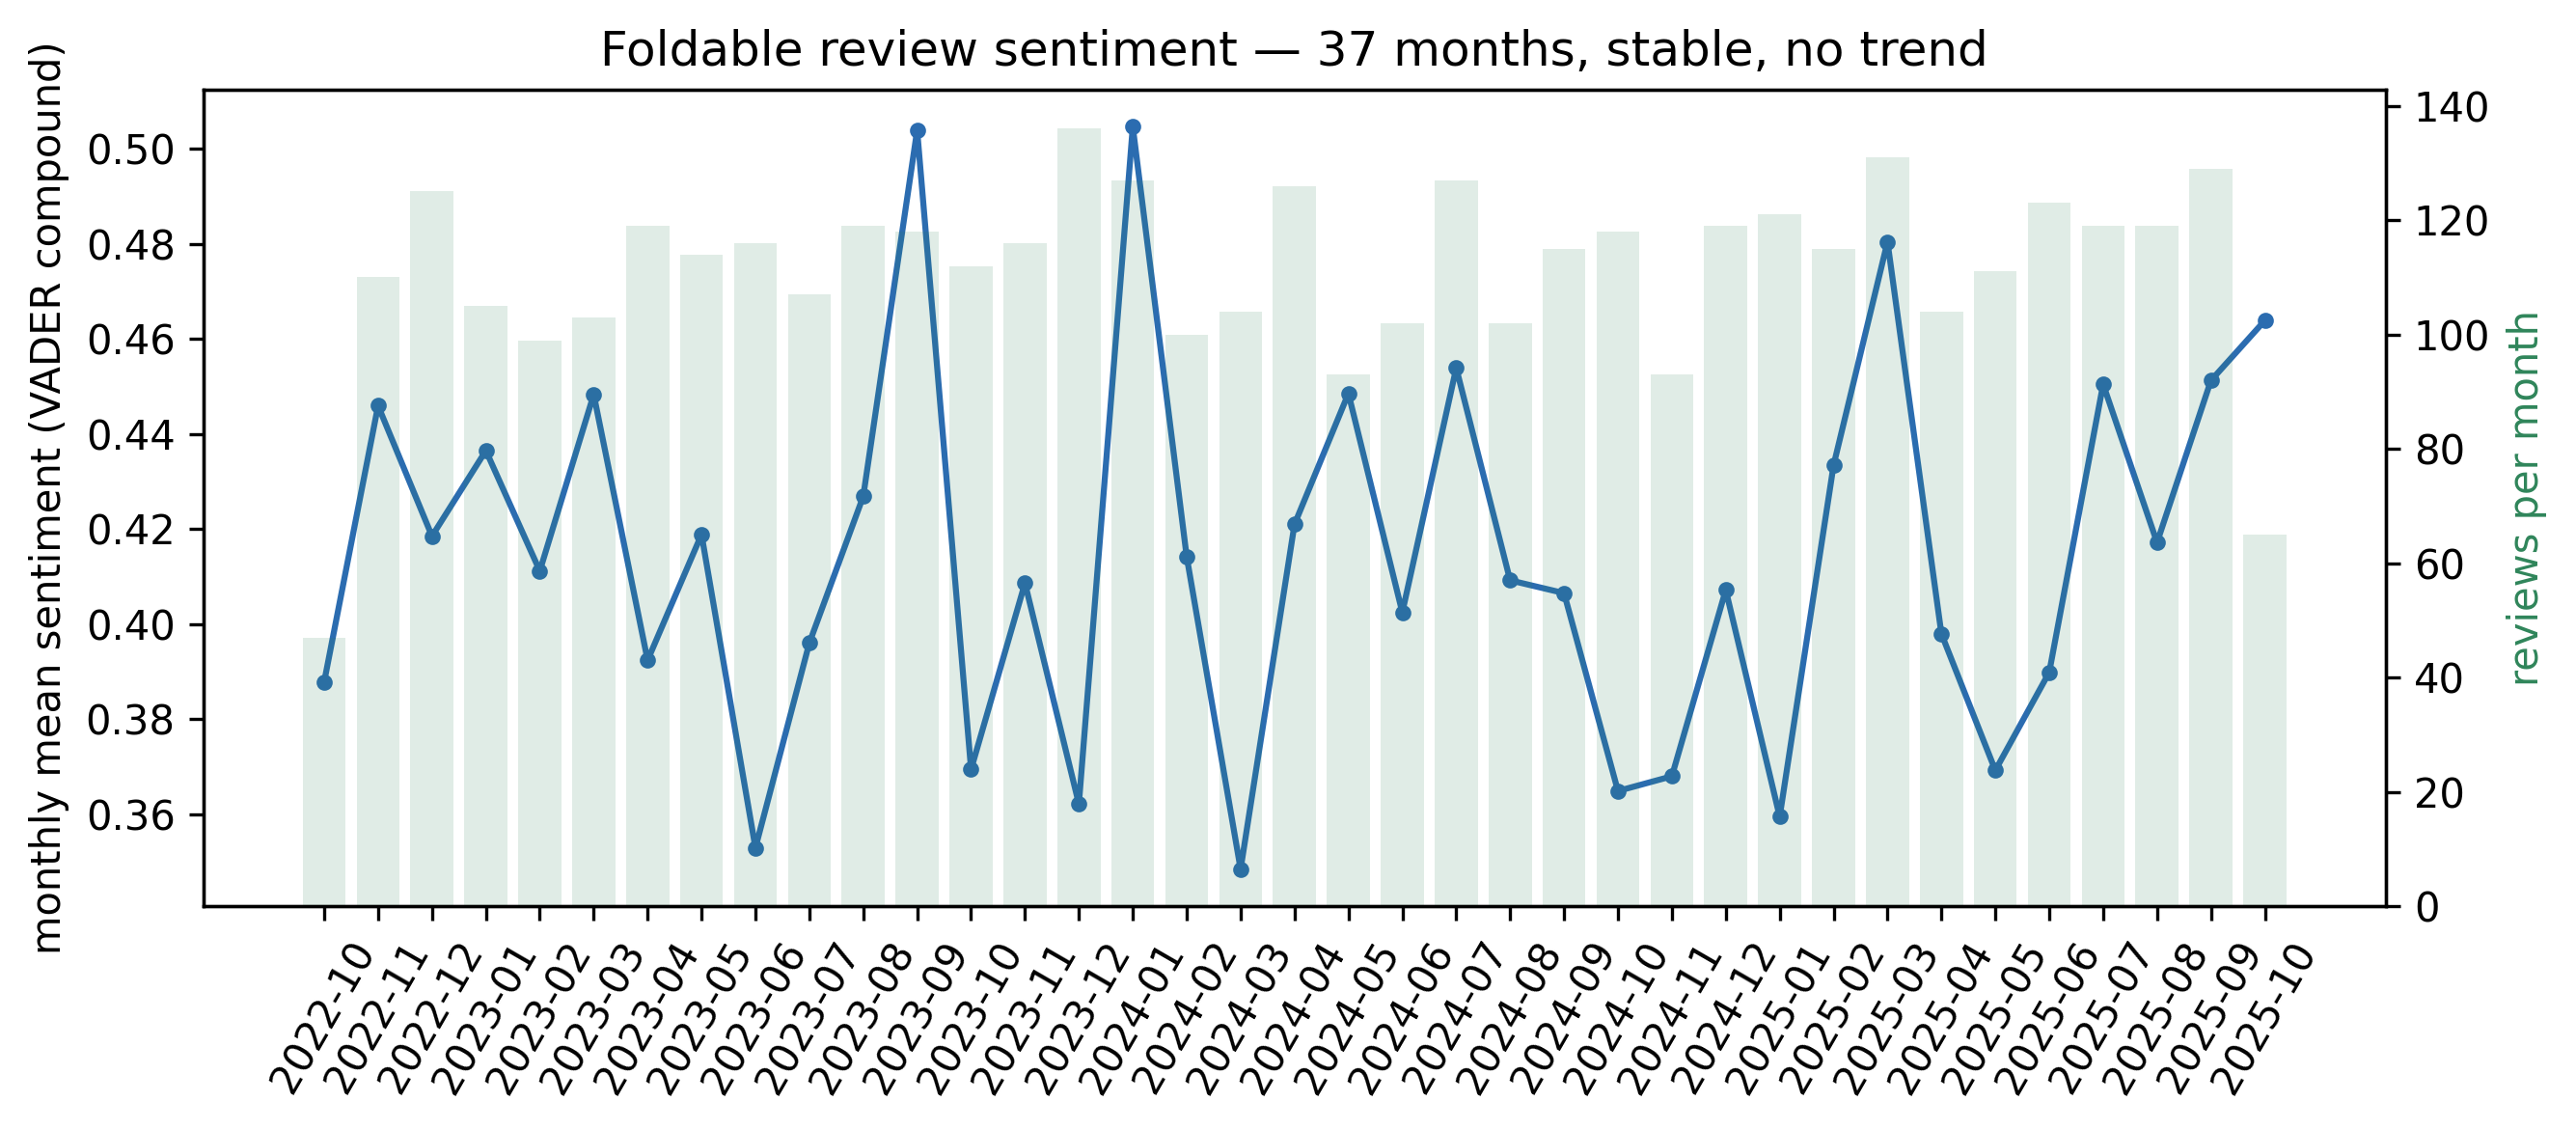

In [3]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(months, y, marker="o", ms=3, color="#2b6cb0", label="mean VADER compound")
ax1.set_ylabel("monthly mean sentiment (VADER compound)")
ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx()
ax2.bar(months, monthly.reviews, alpha=0.15, color="#2f855a", label="review volume")
ax2.set_ylabel("reviews per month", color="#2f855a")
ax1.set_title("Foldable review sentiment — 37 months, stable, no trend")
fig.tight_layout()
fig.savefig(FIGURES / "06_sentiment_series.png", dpi=300)
plt.show()
plt.close(fig)

## 2. Walk-forward evaluation — LSTM vs naive last-value

Split: first 28 months train, last 9 months test. At each test month *t* and
horizon *h*, the model sees only months up to *t − h* (6-month window) and
predicts month *t*; the naive baseline repeats the last observed value. Both
are scored on the same origins. Scalers are fit on training data only.

In [4]:
N_TEST = 9
n_train = len(y) - N_TEST

mu, sd = y[:n_train].mean(), y[:n_train].std()
vol_mu, vol_sd = volume[:n_train].mean(), volume[:n_train].std()
y_s = (y - mu) / sd
vol_s = (volume - vol_mu) / vol_sd

def make_windows(series, vol_series):
    Xs, ys = [], []
    for i in range(WINDOW, len(series)):
        Xs.append(np.stack([series[i - WINDOW:i], vol_series[i - WINDOW:i]], axis=1))
        ys.append(series[i])
    return np.array(Xs), np.array(ys)

X_train, y_train = make_windows(y_s[:n_train], vol_s[:n_train])
print(f"training windows: {X_train.shape}")

def build_lstm(seed: int) -> keras.Sequential:
    tf.random.set_seed(seed)
    model = keras.Sequential([
        keras.layers.Input(shape=(WINDOW, 2)),
        keras.layers.LSTM(16, activation="tanh"),
        keras.layers.Dense(8, activation="relu"),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(0.01), loss="mse")
    return model

lstm = build_lstm(SEED)
lstm.fit(X_train, y_train, epochs=300, batch_size=8, verbose=0)
print("LSTM trained")

def forecast_from(window_sentiment, window_volume, model):
    window = np.stack([window_sentiment, window_volume], axis=1)[None]
    return float(model.predict(window, verbose=0).ravel()[0] * sd + mu)

rows = []
for h in range(1, HORIZON + 1):
    e_lstm, e_naive = [], []
    for t in range(n_train, len(y)):
        origin = t - h
        if origin < WINDOW:
            continue
        pred = forecast_from(y_s[origin - WINDOW:origin], vol_s[origin - WINDOW:origin], lstm)
        e_lstm.append(pred - y[t])
        e_naive.append(y[origin] - y[t])          # last observed value, held for h months
    e_lstm, e_naive = np.array(e_lstm), np.array(e_naive)
    rows.append({"horizon_months": h, "n_eval": len(e_lstm),
                 "lstm_rmse": round(float(np.sqrt((e_lstm ** 2).mean())), 4),
                 "naive_rmse": round(float(np.sqrt((e_naive ** 2).mean())), 4),
                 "lstm_mae": round(float(np.abs(e_lstm).mean()), 4),
                 "naive_mae": round(float(np.abs(e_naive).mean()), 4)})
metrics = pd.DataFrame(rows)
metrics.to_csv(RESULTS / "sentiment_forecast_metrics.csv", index=False)
print(metrics.to_string(index=False))

training windows: (22, 6, 2)


LSTM trained


 horizon_months  n_eval  lstm_rmse  naive_rmse  lstm_mae  naive_mae
              1       9     0.0550      0.0493    0.0452     0.0437
              2       9     0.0481      0.0655    0.0354     0.0509
              3       9     0.0379      0.0601    0.0277     0.0564


## 3. 12-month recursive forecast (ensemble band)

Five LSTMs (different init seeds) roll the series forward month by month from
2025-10; each model feeds its own prediction back in. Review volume is held
at the last observed value (documented assumption — volume is not the target).
The band is the min–max across seeds; it **widens by construction** as errors
compound.

In [5]:
future_months = pd.period_range(months[-1], periods=13, freq="M")[1:].astype(str)
seed_forecasts = []
for seed in range(SEED, SEED + 5):
    m = build_lstm(seed)
    m.fit(X_train, y_train, epochs=300, batch_size=8, verbose=0)
    cur_s, cur_v = list(y_s[-WINDOW:]), list(vol_s[-WINDOW:])
    path = []
    for _ in future_months:
        pred_s = float(m.predict(
            np.stack([cur_s[-WINDOW:], cur_v[-WINDOW:]], axis=1)[None],
            verbose=0).ravel()[0])
        path.append(pred_s * sd + mu)
        cur_s.append(pred_s)          # recursive: feed prediction back in
        cur_v.append(cur_v[-1])      # volume held at last observed value
    seed_forecasts.append(path)
seed_forecasts = np.array(seed_forecasts)   # (5 seeds, 12 months)

forecast = pd.DataFrame({
    "month": future_months,
    "forecast_compound": seed_forecasts.mean(axis=0).round(4),
    "band_low": seed_forecasts.min(axis=0).round(4),
    "band_high": seed_forecasts.max(axis=0).round(4),
    "actual": np.nan,
    "n_model_seeds": 5,
})
forecast.to_csv(RESULTS / "sentiment_forecast.csv", index=False)
print(forecast.to_string(index=False))

  month  forecast_compound  band_low  band_high  actual  n_model_seeds
2025-11             0.3824    0.3583     0.4231     NaN              5
2025-12             0.4581    0.4267     0.4974     NaN              5
2026-01             0.4359    0.3657     0.4901     NaN              5
2026-02             0.4368    0.3683     0.4983     NaN              5
2026-03             0.4338    0.3624     0.4965     NaN              5
2026-04             0.4333    0.3556     0.4969     NaN              5
2026-05             0.4304    0.3397     0.4971     NaN              5
2026-06             0.4316    0.3488     0.4989     NaN              5
2026-07             0.4341    0.3555     0.4981     NaN              5
2026-08             0.4347    0.3546     0.4984     NaN              5
2026-09             0.4348    0.3553     0.4982     NaN              5
2026-10             0.4347    0.3550     0.4983     NaN              5


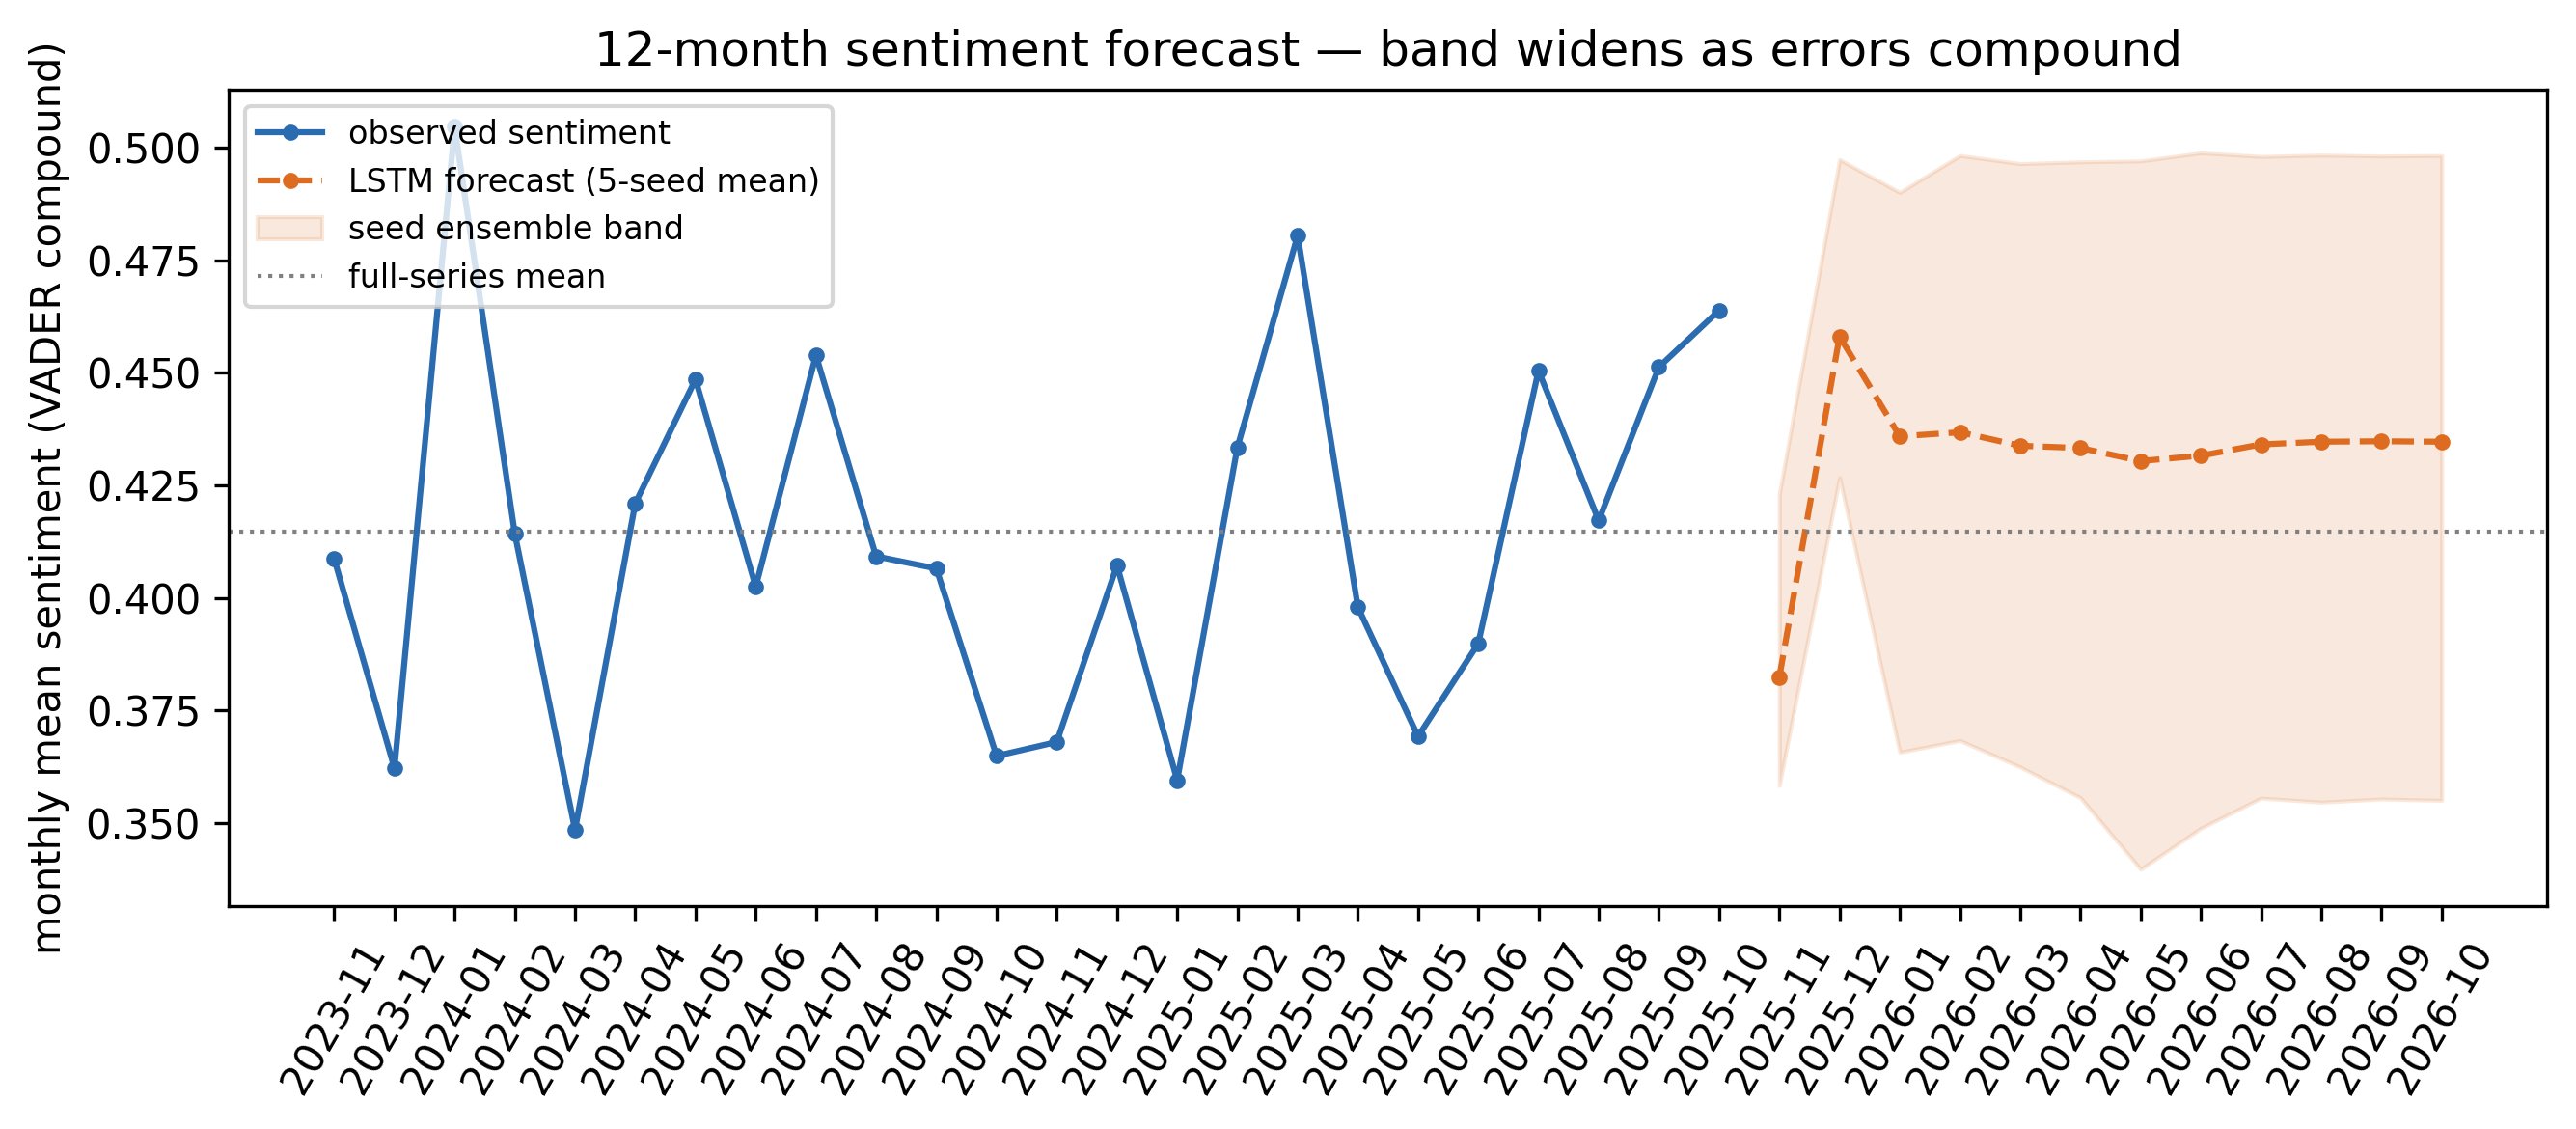

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
show = monthly.tail(24)
ax.plot(show.review_month, show.mean_compound, marker="o", ms=3,
        color="#2b6cb0", label="observed sentiment")
ax.plot(forecast.month, forecast.forecast_compound, "--", marker="o", ms=3,
        color="#dd6b20", label="LSTM forecast (5-seed mean)")
ax.fill_between(forecast.month, forecast.band_low, forecast.band_high,
                alpha=0.15, color="#dd6b20", label="seed ensemble band")
ax.axhline(y.mean(), color="grey", ls=":", lw=1, label="full-series mean")
ax.set_ylabel("monthly mean sentiment (VADER compound)")
ax.tick_params(axis="x", rotation=60)
ax.set_title("12-month sentiment forecast — band widens as errors compound")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "06_sentiment_forecast.png", dpi=300)
plt.show()
plt.close(fig)

## 4. Interpretation and launch-timing recommendation

**Model honesty:**
- The LSTM **beats the naive baseline at the 2- and 3-month horizons** but
  **loses at 1 month** (see `results/sentiment_forecast_metrics.csv`). On a
  37-month series this is exactly the expected picture: the LSTM smooths
  towards the mean, which helps once the noise of the last observation
  dominates, and hurts when the last value is genuinely informative. Neither
  model has business-grade accuracy (RMSE ~0.04–0.07 on a series with std
  0.04 — errors are the size of the series' own variation).
- The forecast band (5 seeds) is wide and widening; treat the 12-month path
  as "sentiment stays in its observed range", not as a trajectory prediction.

**Launch-timing read for the business case:**
- Observed foldable sentiment is **stable and flat** (~0.35–0.50, trend
  ~+0.001/year — noise). There is **no sentiment-based reason to delay or
  accelerate** a 2027 launch within this data.
- The 2027 quarters are 15+ months beyond the series end — beyond any
  defensible horizon of this model, and the corpus behind the sentiment is
  synthetic-like (notebook 04 caveats). The honest launch-timing conclusion:
  **timing-neutral**; the decision should rest on price/segment economics
  (notebooks 02/03, KPI module), not on sentiment momentum.

**Limitations (stated honestly):**
- 37 monthly points from a template corpus; the LSTM has only 22 training
  windows — it cannot learn a meaningful seasonal or momentum structure.
- Recursive forecasting compounds model error; the 12-month band is
  illustrative uncertainty, not calibrated confidence intervals.
- Volume held constant in the rollout; sentiment itself is the only signal.

## Summary — what notebook 06 hands downstream

| Output | Used by |
|---|---|
| `results/sentiment_forecast_metrics.csv` | report: LSTM vs naive evidence table |
| `results/sentiment_forecast.csv` | report + slides: sentiment trajectory context |
| `figures/06_*.png` | report + slides |
| Launch-timing finding (timing-neutral) | report's go/no-go recommendation |